# 👕 Urban Tee: Phân khúc khách hàng bằng K-Means

**Bài toán:** Urban Tee (thời trang áo phông, ~5.000 khách/năm, online + offline) muốn thiết kế ưu đãi
riêng cho từng nhóm khách để **tăng tỷ lệ quay lại, tăng giá trị đơn và giảm lãng phí marketing**.

**Công cụ:** Python (pandas, scikit-learn, matplotlib, seaborn) · Google Colab

## 🔑 Kết quả chính
1. **Nhân khẩu học không giải thích hành vi mua:** tuổi, thu nhập, thành phố, kênh có tương quan ≈ 0 với chi tiêu
   (Chi-square p > 0.05) → phân khúc theo **hành vi** thay vì nhân khẩu học.
2. **4 phân khúc hành vi** (K-Means, K=4, chọn qua Elbow + Silhouette + Davies-Bouldin):

| Phân khúc | % khách | % doanh thu | Đặc điểm | Chiến lược |
|---|---|---|---|---|
| 🥇 Fan trung thành | 22% | 39% | 24 áo/năm, 518k/áo, giảm giá 43% | Đổi giảm giá → đặc quyền VIP |
| 🏷️ Thợ săn sale | 29% | 29% | 22 áo/năm, 328k/áo, giảm giá 38% | Combo để tăng giá trị đơn |
| 💤 Tiết kiệm, ít mua | 25% | 12% | 12 áo/năm, 274k/áo | Voucher ngắn hạn, kênh chi phí thấp |
| 💎 Khách chọn lọc | 24% | 20% | 11 áo/năm, 554k/áo, giảm giá 15% | Hàng mới, không gửi mã giảm giá |

3. **Rủi ro lợi nhuận:** 2 nhóm mua nhiều nhất cũng dùng giảm giá nhiều nhất (38–43%).
4. **Đề xuất nền tảng:** cần hệ thống thành viên/CRM, vì các phân khúc chỉ nhận diện được qua lịch sử mua.

## 🧪 Kiểm chứng mô hình
- So sánh 4 thuật toán: K-Means tốt nhất (Silhouette 0.345, DB 0.887); Hierarchical cho kết quả tương tự (ARI 0.58).
- DBSCAN có Silhouette cao nhất (0.51) nhưng bị loại: gom 97% khách vào 1 cụm, cụm còn lại là artifact của bước capping.
- Phân cụm theo nhân khẩu học tạo 2 cụm có hành vi giống hệt nhau, nên kém hiệu quả cho marketing.

## ⚠️ Hạn chế
- 32,5% khách ghi 18 tuổi, chi tiêu chặn sàn 1 triệu (nghi lỗi nhập liệu).
- Không có dữ liệu thời gian (ngày mua, số đơn), nên chưa tính được RFM / tỷ lệ rời bỏ.
- Chiến lược đề xuất cần kiểm chứng bằng A/B test.

## 📑 Mục lục
1. Hiểu bài toán · 2. EDA · 3. Tiền xử lý · 4. Chọn K · 5. K-Means · 6. Chiến lược ·
7. Trực quan hóa · 8. So sánh thuật toán · 9. Nhân khẩu học vs Hành vi

## 1. Setup & data

In [1]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.2f}'.format)

if os.path.exists('data/customer_clustering_dataset_final_v2.csv'):   # chạy từ repo GitHub
    BASE = '.'
    DATA_PATH = 'data/customer_clustering_dataset_final_v2.csv'
else:                                                                 # chạy trên Colab với Google Drive
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/Colab Notebooks'
    DATA_PATH = f'{BASE}/customer_clustering_dataset_final_v2.csv'

os.makedirs(f'{BASE}/outputs', exist_ok=True)   # tạo thư mục lưu biểu đồ

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

Mounted at /content/drive
(5000, 9)


,customer_id,age,income_million_vnd,total_product_purchase,total_money_purchase_million_vnd,discount_using_rate,location,payment_method,buying_channel
0,CUST05000,31,15.99,11,2.64,0.13,Đà Nẵng,Cash,Offline
1,CUST04999,20,5.00,28,8.08,0.55,Huế,Credit Card,Offline
2,CUST04998,26,12.91,8,3.16,0.09,Hồ Chí Minh,Bank Transfer,Offline
3,CUST04997,20,20.46,17,4.47,0.26,Hà Nội,Bank Transfer,Online
4,CUST04996,35,5.81,16,3.86,0.24,Hà Nội,Bank Transfer,Offline


## 2. Exploratory data analysis (EDA)

In [2]:
df.info()
print('\nGiá trị thiếu:\n', df.isna().sum())
print('\nSố dòng trùng:', df.duplicated().sum())
print('Số customer_id trùng:', df.customer_id.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   customer_id                       5000 non-null   object 
 1   age                               5000 non-null   int64  
 2   income_million_vnd                5000 non-null   float64
 3   total_product_purchase            5000 non-null   int64  
 4   total_money_purchase_million_vnd  5000 non-null   float64
 5   discount_using_rate               5000 non-null   float64
 6   location                          5000 non-null   object 
 7   payment_method                    5000 non-null   object 
 8   buying_channel                    5000 non-null   object 
dtypes: float64(3), int64(2), object(4)
memory usage: 351.7+ KB

Giá trị thiếu:
 customer_id                         0
age                                 0
income_million_vnd                  0
total_

,count,mean,std,min,25%,50%,75%,max
age,5000.00,26.05,9.37,18.00,18.00,23.00,31.00,60.00
income_million_vnd,5000.00,14.33,9.37,5.00,6.83,11.85,19.06,50.00
total_product_purchase,5000.00,17.56,7.02,1.00,13.00,17.00,22.00,44.00
total_money_purchase_million_vnd,5000.00,7.05,3.65,1.00,4.37,6.58,9.28,25.16
discount_using_rate,5000.00,0.28,0.16,0.01,0.16,0.26,0.38,0.84


In [3]:
num_cols = ['age','income_million_vnd','total_product_purchase',
            'total_money_purchase_million_vnd','discount_using_rate']
for c in num_cols:
    mn, mx = df[c].min(), df[c].max()
    print(f'{c:35s} min={mn:<6} (n={(df[c]==mn).sum():4d}) | max={mx:<6} (n={(df[c]==mx).sum():4d})')

age                                 min=18     (n=1626) | max=60     (n=  40)
income_million_vnd                  min=5.0    (n= 768) | max=50.0   (n=  33)
total_product_purchase              min=1      (n=  58) | max=44     (n=   1)
total_money_purchase_million_vnd    min=1.0    (n= 145) | max=25.16  (n=   1)
discount_using_rate                 min=0.01   (n=  13) | max=0.84   (n=   1)


**📌 Insight:** 32,5% khách ghi đúng 18 tuổi, 15% thu nhập đúng 5 triệu, cao bất thường.
**➡️ Hàm ý:** Nhiều khả năng giá trị bị chặn sàn khi nhập liệu (khách <18 hoặc không khai báo).
Không dùng tuổi/thu nhập làm biến phân cụm chính; ghi nhận đây là hạn chế dữ liệu.

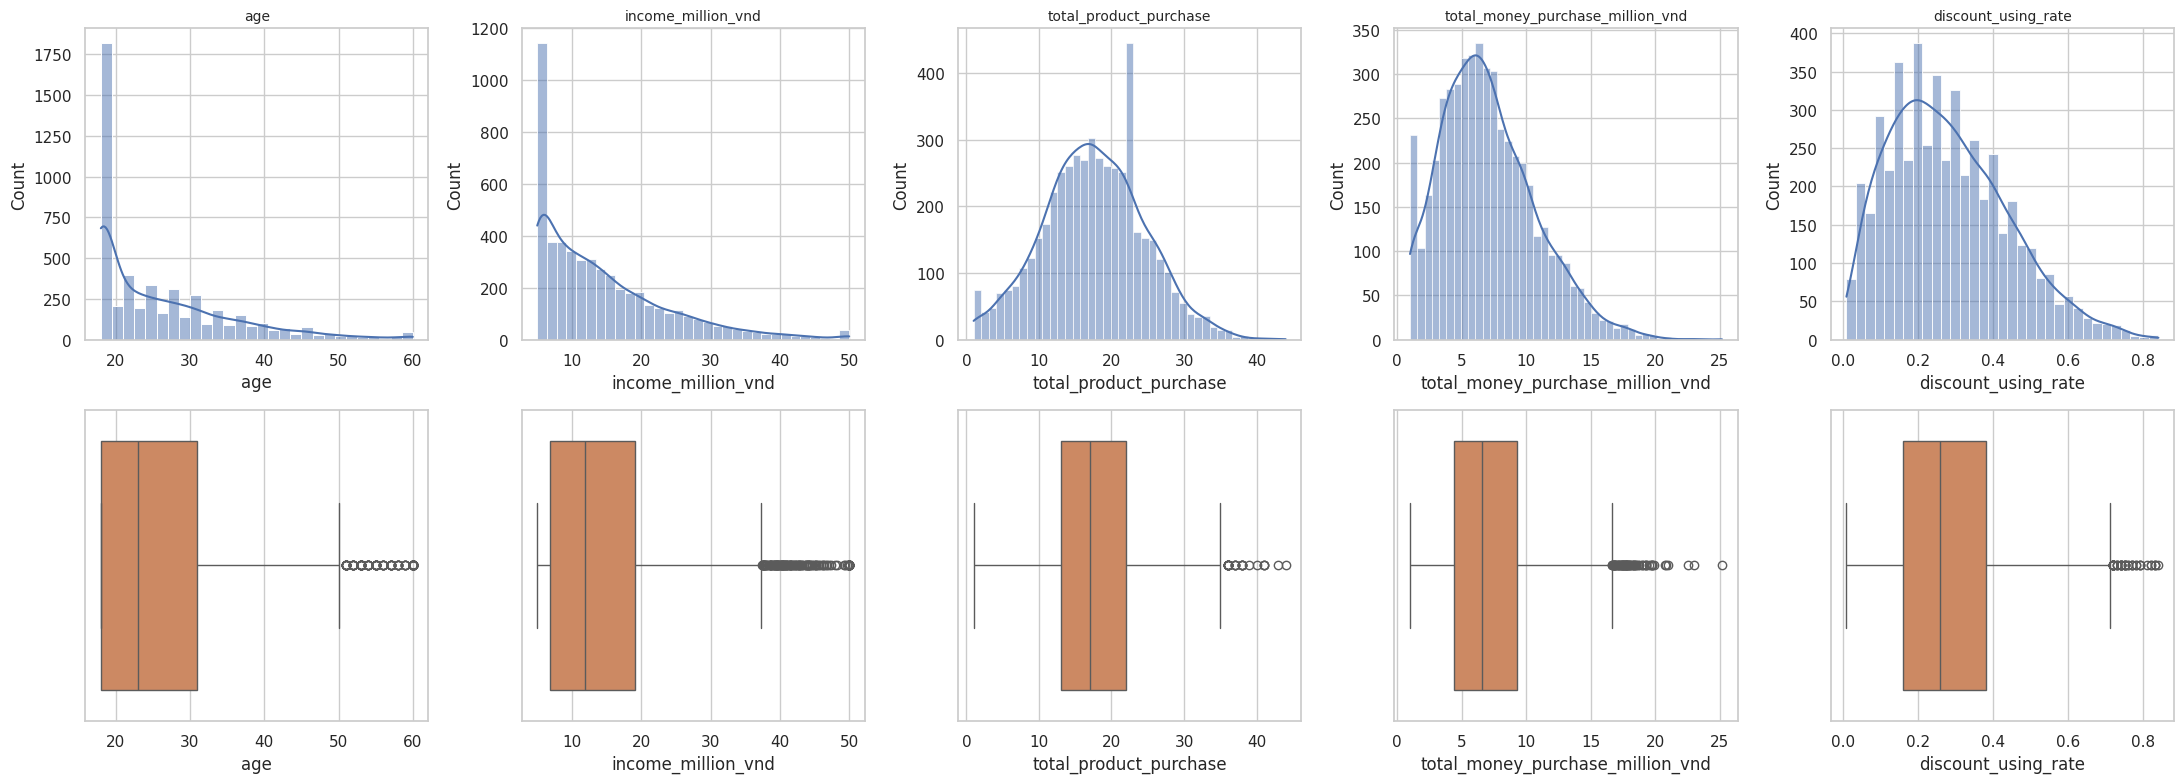

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], kde=True, ax=axes[0, i], color='#4C72B0')
    axes[0, i].set_title(c, fontsize=10)
    sns.boxplot(x=df[c], ax=axes[1, i], color='#DD8452')
plt.tight_layout()
plt.savefig(f'{BASE}/outputs/01_distributions.png', dpi=150)
plt.show()

**📌 Insight:** Số SP/năm và chi tiêu có phân phối gần chuẩn, hơi lệch phải
(median ~17 áo, ~6,6 triệu/năm). Có một số khách chi tiêu rất cao (đến 25 triệu), là ngoại lai hợp lệ.
**➡️ Hàm ý:** Giữ ngoại lai vì đó là khách giá trị cao; sẽ chuẩn hóa dữ liệu trước khi chạy K-means.

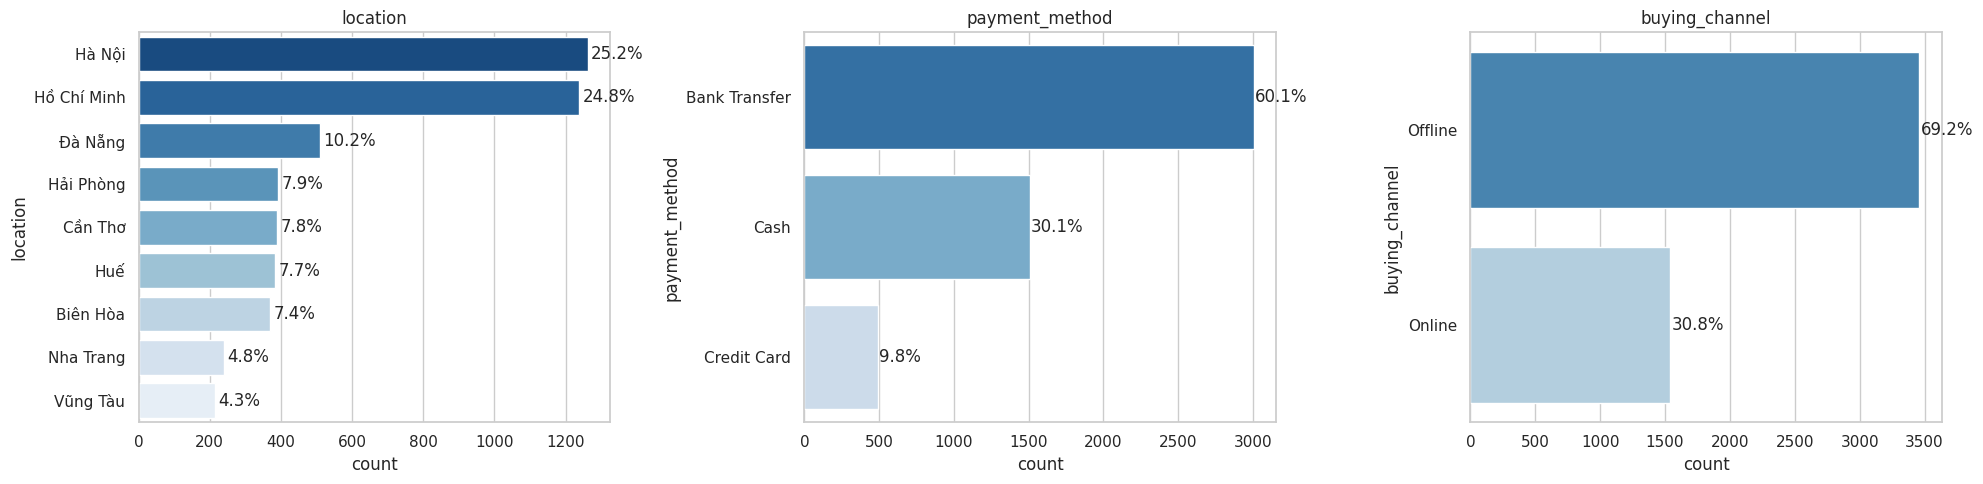

In [5]:
cat_cols = ['location','payment_method','buying_channel']
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, c in zip(axes, cat_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, y=c, order=order, ax=ax, palette='Blues_r')
    for p in ax.patches:
        ax.text(p.get_width()+10, p.get_y()+p.get_height()/2,
                f'{p.get_width()/len(df):.1%}', va='center')
    ax.set_title(c)
plt.tight_layout()
plt.savefig(f'{BASE}/outputs/02_categorical.png', dpi=150)
plt.show()

**📌 Insight:** Hà Nội + TP.HCM = 50% khách. Offline chiếm 69%, online 31%.
Chuyển khoản 60%, tiền mặt 30%, thẻ tín dụng 10%.
**➡️ Hàm ý:** Cửa hàng vật lý vẫn là kênh chính; online còn dư địa tăng trưởng.
Ưu đãi nên ưu tiên triển khai tại HN/HCM trước.

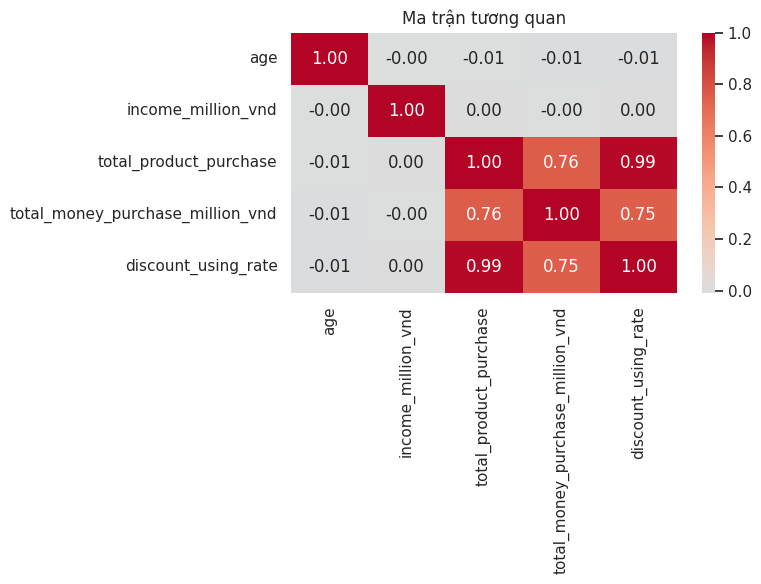

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Ma trận tương quan')
plt.tight_layout()
plt.savefig(f'{BASE}/outputs/03_correlation.png', dpi=150)
plt.show()

**📌 Insight:**
- Số SP và tỷ lệ dùng giảm giá tương quan r = 0.99: khách mua càng nhiều càng săn mã giảm giá.
- Tuổi và thu nhập tương quan ≈ 0 với mọi biến hành vi.
**➡️ Hàm ý:** (1) Hai biến gần trùng lặp, chỉ giữ một khi phân cụm.
(2) Nhân khẩu học không giải thích được hành vi, nên phân cụm theo hành vi.

In [7]:
df['age_group'] = pd.cut(df.age, bins=[17,22,30,40,60],
                         labels=['18-22','23-30','31-40','41-60'])
for c in ['buying_channel','payment_method','age_group']:
    print(f'\n=== {c} ===')
    display(df.groupby(c)[num_cols[1:]].mean().round(2))


=== buying_channel ===


,income_million_vnd,total_product_purchase,total_money_purchase_million_vnd,discount_using_rate
buying_channel,,,,
Offline,14.22,17.62,7.05,0.28
Online,14.59,17.40,7.06,0.28



=== payment_method ===


,income_million_vnd,total_product_purchase,total_money_purchase_million_vnd,discount_using_rate
payment_method,,,,
Bank Transfer,14.20,17.46,7.02,0.28
Cash,14.49,17.67,7.06,0.28
Credit Card,14.69,17.78,7.22,0.29



=== age_group ===


,income_million_vnd,total_product_purchase,total_money_purchase_million_vnd,discount_using_rate
age_group,,,,
18-22,14.34,17.61,7.13,0.28
23-30,14.49,17.48,6.88,0.28
31-40,13.97,17.52,7.02,0.28
41-60,14.52,17.52,7.15,0.28


**📌 Insight:** Chi tiêu TB gần như bằng nhau giữa các nhóm tuổi, kênh mua, phương thức thanh toán
(~6,9–7,2 triệu/năm, chênh < 5%).
**➡️ Hàm ý:** Chia khách theo tuổi/kênh để khuyến mãi sẽ không hiệu quả, nên dùng K-means trên biến hành vi.

In [8]:
df['price_per_item_k'] = df['total_money_purchase_million_vnd'] / df['total_product_purchase'] * 1000
df['income_group'] = pd.cut(df['income_million_vnd'], [0, 10, 20, 30, 50],
                            labels=['≤10tr', '10-20tr', '20-30tr', '30-50tr'])

print(f"Giá TB mỗi áo: {df['price_per_item_k'].mean():.0f}k | median: {df['price_per_item_k'].median():.0f}k")
print('\nTỷ trọng nhóm tuổi:\n', df['age_group'].value_counts(normalize=True).sort_index().round(3))
print('\nTỷ trọng nhóm thu nhập:\n', df['income_group'].value_counts(normalize=True).sort_index().round(3))

Giá TB mỗi áo: 412k | median: 404k

Tỷ trọng nhóm tuổi:
 age_group
18-22   0.48
23-30   0.26
31-40   0.17
41-60   0.09
Name: proportion, dtype: float64

Tỷ trọng nhóm thu nhập:
 income_group
≤10tr     0.42
10-20tr   0.36
20-30tr   0.15
30-50tr   0.07
Name: proportion, dtype: float64


**📌 Insight (Cell 8):** Giá TB ~412k/áo (median 404k), phân khúc tầm trung.
74% khách 18–30 tuổi, 78% thu nhập ≤20tr/tháng.
**➡️ Hàm ý:** Khách trẻ, ngân sách hạn chế, nhạy cảm giá. Ưu đãi dạng combo/bundle
sẽ tăng giá trị đơn mà không cần giảm sâu từng áo.

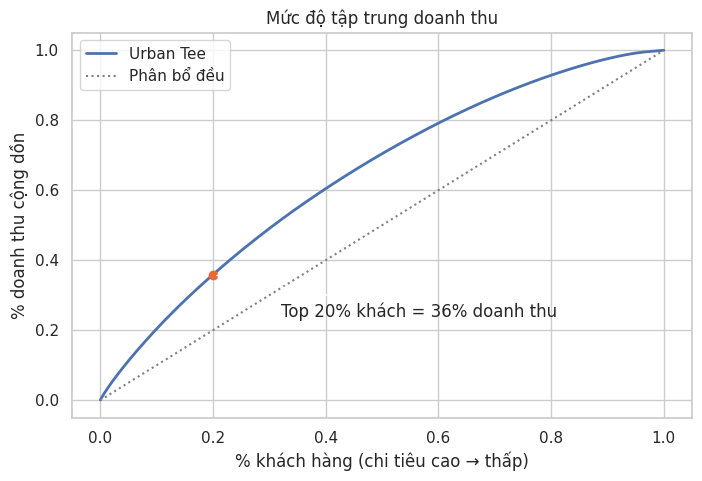

In [9]:
s = df['total_money_purchase_million_vnd'].sort_values(ascending=False).values
cum = s.cumsum() / s.sum()
x = np.arange(1, len(s) + 1) / len(s)
top20 = cum[int(len(s) * 0.2) - 1]

plt.figure(figsize=(8, 5))
plt.plot(x, cum, lw=2, label='Urban Tee')
plt.plot([0, 1], [0, 1], ls=':', color='gray', label='Phân bổ đều')
plt.scatter([0.2], [top20], color='#eb6834', zorder=3)
plt.annotate(f'Top 20% khách = {top20:.0%} doanh thu', xy=(0.2, top20), xytext=(0.32, top20 - 0.12),
             arrowprops=dict(arrowstyle='->'))
plt.xlabel('% khách hàng (chi tiêu cao → thấp)'); plt.ylabel('% doanh thu cộng dồn')
plt.title('Mức độ tập trung doanh thu'); plt.legend()
plt.savefig(f'{BASE}/outputs/04_pareto.png', dpi=150, bbox_inches='tight')
plt.show()

**📌 Insight (Cell 9):** Top 20% khách chỉ tạo 36% doanh thu, doanh thu phân tán đều.
**➡️ Hàm ý:** Không nên chỉ tập trung vào VIP; cần phân khúc thành nhiều nhóm
với chiến lược riêng, đó là lý do dùng phân cụm.

### 2.5 Tóm tắt EDA

**Chân dung khách hàng chính:** 18–30 tuổi (74%), thu nhập ≤20tr (78%), sống ở HN/HCM (50%),
mua tại cửa hàng (69%), thanh toán chuyển khoản (60%). Trung bình ~17,5 áo/năm,
chi ~7 triệu/năm, ~412k/áo.

**4 phát hiện chính:**
1. **Nhân khẩu học không giải thích hành vi:** tuổi, thu nhập, kênh, thanh toán có tương quan ≈ 0 với chi tiêu;
   chi tiêu TB giữa các nhóm chênh < 5%. → Phải phân khúc theo **hành vi**.
2. **Khách mua nhiều = khách săn sale:** số SP và tỷ lệ dùng giảm giá có r = 0.99.
   → Rủi ro bào mòn biên lợi nhuận ở nhóm trung thành.
3. **Doanh thu phân tán:** top 20% khách = 36% doanh thu. → Cần chiến lược cho nhiều tệp, không chỉ VIP.
4. **Online còn nhỏ (31%)** dù khách rất trẻ. → Cơ hội chuyển dịch khách sang online.

**Hạn chế dữ liệu:** 32,5% khách ghi 18 tuổi, 15% thu nhập = 5tr (nghi chặn sàn);
không có dữ liệu thời gian (ngày mua gần nhất, số đơn), nên không tính được RFM đầy đủ.

## 3. Feature selection & preprocessing

In [10]:
# 3 biến hành vi dùng để phân cụm
features = ['total_product_purchase',            # mua nhiều hay ít
            'total_money_purchase_million_vnd',  # chi tiêu nhiều hay ít
            'price_per_item_k']                  # mua áo đắt hay rẻ

X = df[features].copy()

# Độ lệch phân phối (skewness): |skew| > 1 là lệch mạnh
print('Skewness:\n', X.skew().round(2))

# Đếm ngoại lai theo quy tắc IQR
Q1, Q3 = X.quantile(0.25), X.quantile(0.75)
IQR = Q3 - Q1
outlier = ((X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR))
print('\nSố ngoại lai mỗi biến:\n', outlier.sum())
print('Tổng số khách có ít nhất 1 ngoại lai:', outlier.any(axis=1).sum())

# Xem 5 khách có giá/áo cao nhất
display(df.nlargest(5, 'price_per_item_k')[['customer_id'] + features])

Skewness:
 total_product_purchase             0.09
total_money_purchase_million_vnd   0.68
price_per_item_k                   2.11
dtype: float64

Số ngoại lai mỗi biến:
 total_product_purchase              30
total_money_purchase_million_vnd    69
price_per_item_k                    74
dtype: int64
Tổng số khách có ít nhất 1 ngoại lai: 160


,customer_id,total_product_purchase,total_money_purchase_million_vnd,price_per_item_k
4054,CUST00946,1,2.59,2590.00
2250,CUST02750,1,2.12,2120.00
4612,CUST00388,1,2.12,2120.00
2367,CUST02633,1,2.02,2020.00
2271,CUST02729,1,1.71,1710.00


**📌 Insight:** Giá/áo lệch mạnh (skew 2.11), 74 ngoại lai. 58/74 là khách chỉ mua 1 áo.
Khách mua 1–3 áo có giá TB 849k/áo, gấp đôi phần còn lại (~400k).
Nguyên nhân: chi tiêu bị chặn sàn ở 1 triệu (145 khách), nên giá/áo của khách mua ít bị thổi phồng.
**➡️ Quyết định:** Giữ tất cả khách (nhóm mua ít là tệp thật, cần kích hoạt),
nhưng capping giá/áo tại ngưỡng IQR trên trước khi chuẩn hóa.

Ngưỡng capping giá/áo: 816k
Skewness sau capping:
 total_product_purchase             0.09
total_money_purchase_million_vnd   0.68
price_per_item_k                   0.30
dtype: float64


,total_product_purchase,total_money_purchase_million_vnd,price_per_item_k
count,5000.00,5000.00,5000.00
mean,0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-2.36,-1.66,-2.48
25%,-0.65,-0.73,-0.75
50%,-0.08,-0.13,-0.03
75%,0.63,0.61,0.71
max,3.77,4.96,2.91


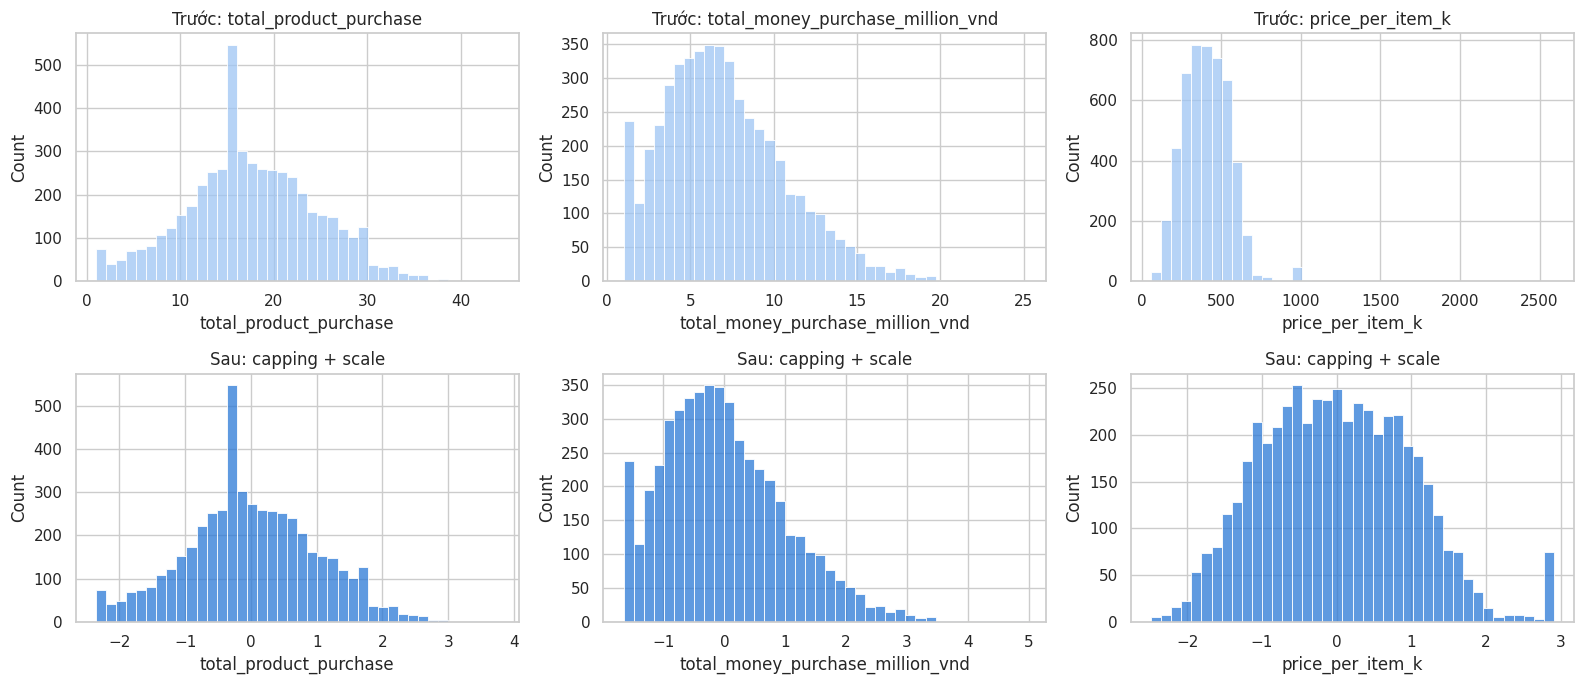

In [11]:
from sklearn.preprocessing import StandardScaler

X = df[features].copy()

# 1. Capping giá/áo tại ngưỡng IQR trên
q1, q3 = X['price_per_item_k'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
X['price_per_item_k'] = X['price_per_item_k'].clip(upper=upper)
print(f'Ngưỡng capping giá/áo: {upper:.0f}k')
print('Skewness sau capping:\n', X.skew().round(2))

# 2. Chuẩn hóa: đưa các biến về cùng thang đo (mean=0, std=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)
display(X_scaled_df.describe().round(2))

# 3. So sánh phân phối trước và sau
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for i, c in enumerate(features):
    sns.histplot(df[c], bins=40, ax=axes[0, i], color='#9ec5f4'); axes[0, i].set_title(f'Trước: {c}')
    sns.histplot(X_scaled_df[c], bins=40, ax=axes[1, i], color='#2a78d6'); axes[1, i].set_title('Sau: capping + scale')
plt.tight_layout()
plt.savefig(f'{BASE}/outputs/05_preprocessing.png', dpi=150, bbox_inches='tight')
plt.show()

**📌 Kết quả tiền xử lý:** Capping giá/áo tại 816k giảm skewness từ 2.11 xuống 0.30.
Sau StandardScaler, 3 biến có mean=0, std=1, nên có trọng số ngang nhau khi tính khoảng cách.

## 4. Choosing the number of clusters (K)

,K,inertia,silhouette,davies_bouldin
0,2,9041.92,0.36,1.06
1,3,6378.48,0.35,0.97
2,4,4881.64,0.34,0.89
3,5,3965.10,0.35,0.86
4,6,3367.64,0.34,0.87
5,7,2892.05,0.33,0.86
6,8,2567.43,0.33,0.82
7,9,2250.87,0.34,0.83
8,10,2001.08,0.34,0.80


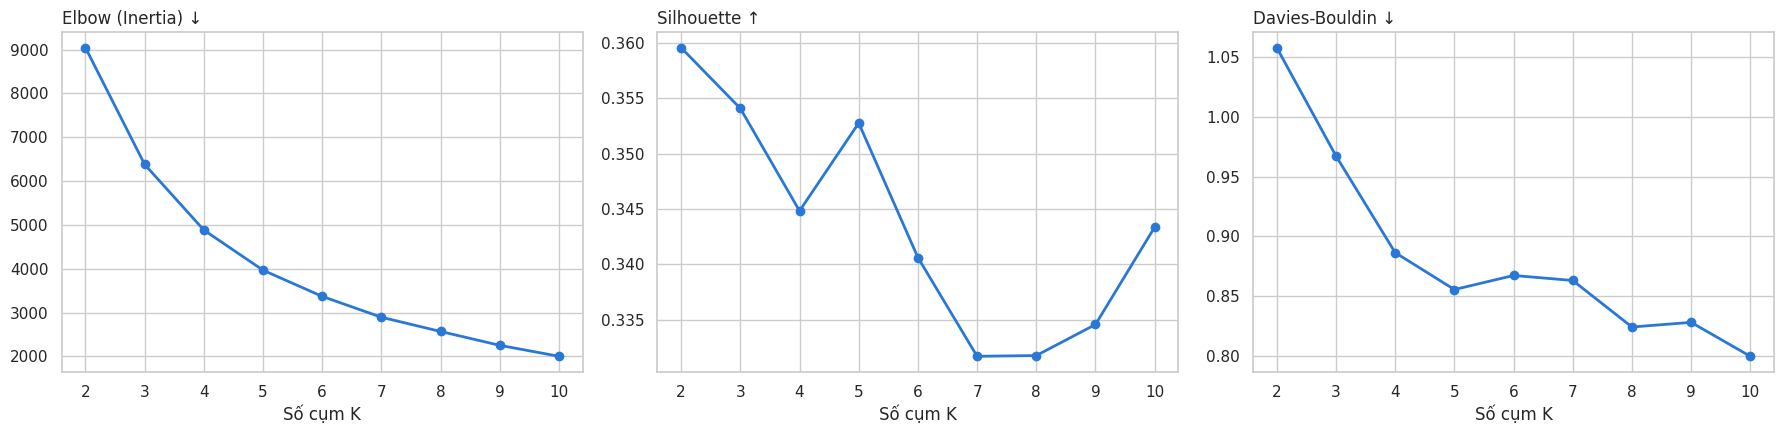

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

K_range = range(2, 11)
results = []
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    results.append({'K': k,
                    'inertia': km.inertia_,
                    'silhouette': silhouette_score(X_scaled, labels),
                    'davies_bouldin': davies_bouldin_score(X_scaled, labels)})
res = pd.DataFrame(results)
display(res.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (col, title) in zip(axes, [('inertia', 'Elbow (Inertia) ↓'),
                                   ('silhouette', 'Silhouette ↑'),
                                   ('davies_bouldin', 'Davies-Bouldin ↓')]):
    ax.plot(res['K'], res[col], marker='o', lw=2, color='#2a78d6')
    ax.set_title(title, loc='left'); ax.set_xlabel('Số cụm K'); ax.set_xticks(list(K_range))
plt.tight_layout()
plt.savefig(f'{BASE}/outputs/06_choose_k.png', dpi=150, bbox_inches='tight')
plt.show()

**📌 Chọn K = 4**
- Elbow: inertia giảm chậm lại từ K=4 (giảm 23,5% từ K=3→4, chỉ 18,8% từ 4→5).
- Davies-Bouldin giảm mạnh đến K=4 (0.89) rồi đi ngang.
- Silhouette ổn định ~0.34 ở mọi K, nên dữ liệu không có cụm tự nhiên rõ ràng;
  K-means được dùng để phân khúc phục vụ marketing, nên ưu tiên K dễ diễn giải và triển khai.
- 4 nhóm là số lượng vừa đủ để thiết kế ưu đãi riêng mà không quá tải vận hành.

## 5. K-Means (K = 4) & segment profiles

In [13]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)

profile_cols = ['total_product_purchase', 'total_money_purchase_million_vnd',
                'price_per_item_k', 'discount_using_rate', 'age', 'income_million_vnd']

profile = df.groupby('cluster')[profile_cols].mean().round(2)
profile['n_customers'] = df['cluster'].value_counts().sort_index()
profile['%_customers'] = (profile['n_customers'] / len(df) * 100).round(1)
profile['%_revenue'] = (df.groupby('cluster')['total_money_purchase_million_vnd'].sum()
                        / df['total_money_purchase_million_vnd'].sum() * 100).round(1)
display(profile)

# So với trung bình toàn bộ: >1 là cao hơn TB, <1 là thấp hơn TB
display((df.groupby('cluster')[profile_cols[:4]].mean() / df[profile_cols[:4]].mean()).round(2)
        .style.background_gradient(cmap='RdBu_r', vmin=0.4, vmax=1.6, axis=None))

,total_product_purchase,total_money_purchase_million_vnd,price_per_item_k,discount_using_rate,age,income_million_vnd,n_customers,%_customers,%_revenue
cluster,,,,,,,,,
0,24.03,12.29,517.99,0.43,26.03,14.05,1121,22.40,39.10
1,22.07,7.10,327.90,0.38,26.10,14.33,1441,28.80,29.00
2,12.36,3.32,273.89,0.16,26.07,14.12,1230,24.60,11.60
3,11.46,5.92,553.75,0.15,26.01,14.82,1208,24.20,20.30


,total_product_purchase,total_money_purchase_million_vnd,price_per_item_k,discount_using_rate
cluster,,,,
0,1.370000,1.740000,1.260000,1.530000
1,1.260000,1.010000,0.800000,1.350000
2,0.700000,0.470000,0.670000,0.580000
3,0.650000,0.840000,1.340000,0.520000


### Kết quả phân cụm (K=4)
| Cụm | Tên | % khách | % doanh thu | Đặc điểm |
|---|---|---|---|---|
| 0 | Fan trung thành | 22% | 39% | Mua nhiều (24 áo), giá cao (518k), nhưng dùng giảm giá nhiều nhất (43%) |
| 1 | Thợ săn sale | 29% | 29% | Mua nhiều (22 áo), giá thấp (328k), dùng giảm giá 38% |
| 2 | Tiết kiệm, ít mua | 25% | 12% | Mua ít (12 áo), giá thấp (274k), chi thấp nhất (3,3tr) |
| 3 | Khách chọn lọc | 24% | 20% | Mua ít (11 áo), giá cao nhất (554k), ít cần giảm giá (15%) |

**📌 Insight:** Tuổi (~26) và thu nhập 14tr giống nhau ở cả 4 cụm. Các nhóm chỉ khác nhau
ở hành vi mua, nên marketing phải nhắm theo dữ liệu mua hàng (CRM), không theo nhân khẩu học.

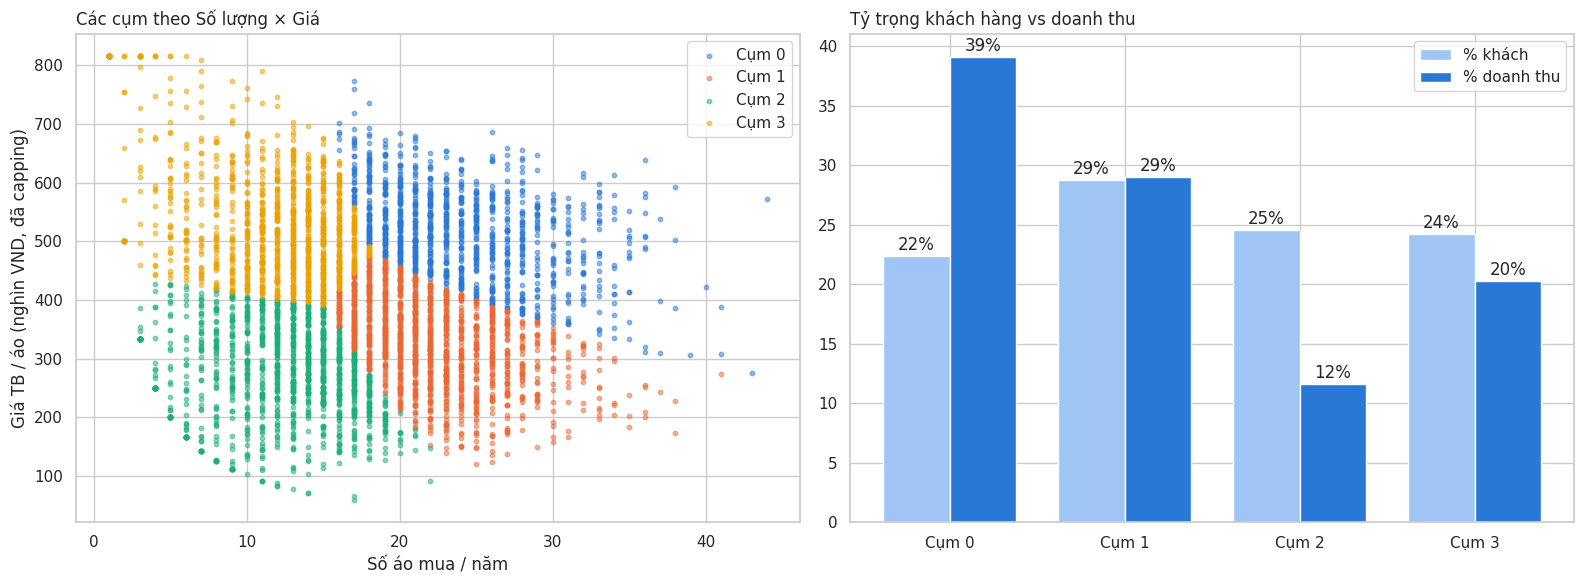

In [14]:
palette = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Số áo vs Giá/áo: 2 trục chính phân tách các cụm
for c in sorted(df['cluster'].unique()):
    d = df[df['cluster'] == c]
    axes[0].scatter(d['total_product_purchase'], d['price_per_item_k'].clip(upper=816),
                    s=10, alpha=0.5, color=palette[c], label=f'Cụm {c}')
axes[0].set(xlabel='Số áo mua / năm', ylabel='Giá TB / áo (nghìn VND, đã capping)')
axes[0].set_title('Các cụm theo Số lượng × Giá', loc='left'); axes[0].legend()

# Tỷ trọng khách vs doanh thu
x = np.arange(len(profile)); w = 0.38
axes[1].bar(x - w/2, profile['%_customers'], w, label='% khách', color='#9ec5f4')
axes[1].bar(x + w/2, profile['%_revenue'], w, label='% doanh thu', color='#2a78d6')
for i in x:
    axes[1].text(i - w/2, profile['%_customers'].iloc[i] + 0.5, f"{profile['%_customers'].iloc[i]:.0f}%", ha='center')
    axes[1].text(i + w/2, profile['%_revenue'].iloc[i] + 0.5, f"{profile['%_revenue'].iloc[i]:.0f}%", ha='center')
axes[1].set_xticks(x, [f'Cụm {c}' for c in profile.index])
axes[1].set_title('Tỷ trọng khách hàng vs doanh thu', loc='left'); axes[1].legend()

plt.tight_layout()
plt.savefig(f'{BASE}/outputs/07_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
cluster_names = {0: 'Fan trung thành', 1: 'Thợ săn sale',
                 2: 'Tiết kiệm, ít mua', 3: 'Khách chọn lọc'}
df['segment'] = df['cluster'].map(cluster_names)

# Tỷ lệ kênh mua, thanh toán theo cụm
for col in ['buying_channel', 'payment_method']:
    print(f'\n=== {col} (% theo hàng) ===')
    display((pd.crosstab(df['segment'], df[col], normalize='index') * 100).round(1))

# Phân bổ cụm tại các thành phố lớn
print('\n=== % mỗi cụm trong từng thành phố ===')
display((pd.crosstab(df['location'], df['segment'], normalize='index') * 100).round(1))

# Lưu kết quả phân cụm để làm dashboard sau
df.to_csv(f'{BASE}/outputs/customers_with_segments.csv', index=False, encoding='utf-8-sig')


=== buying_channel (% theo hàng) ===


buying_channel,Offline,Online
segment,,
Fan trung thành,68.50,31.50
Khách chọn lọc,70.00,30.00
Thợ săn sale,70.00,30.00
"Tiết kiệm, ít mua",68.20,31.80



=== payment_method (% theo hàng) ===


payment_method,Bank Transfer,Cash,Credit Card
segment,,,
Fan trung thành,60.00,29.60,10.30
Khách chọn lọc,59.00,29.90,11.10
Thợ săn sale,58.80,31.60,9.50
"Tiết kiệm, ít mua",62.70,29.00,8.30



=== % mỗi cụm trong từng thành phố ===


segment,Fan trung thành,Khách chọn lọc,Thợ săn sale,"Tiết kiệm, ít mua"
location,,,,
Biên Hòa,27.60,25.10,25.10,22.20
Cần Thơ,23.70,19.50,31.90,24.90
Huế,21.40,26.80,27.60,24.20
Hà Nội,21.70,24.60,28.10,25.70
Hải Phòng,17.60,27.50,30.50,24.40
Hồ Chí Minh,24.00,22.50,29.30,24.20
Nha Trang,25.40,23.30,27.50,23.80
Vũng Tàu,22.40,23.80,29.40,24.30
Đà Nẵng,18.80,26.10,29.80,25.30


In [16]:
from scipy.stats import chi2_contingency

for col in ['location', 'buying_channel', 'payment_method']:
    ct = pd.crosstab(df[col], df['segment'])
    chi2, p, dof, _ = chi2_contingency(ct)
    verdict = 'CÓ khác biệt' if p < 0.05 else 'KHÔNG khác biệt có ý nghĩa'
    print(f'{col:18s} chi2={chi2:6.1f}  p-value={p:.3f}  → {verdict}')

location           chi2=  29.5  p-value=0.200  → KHÔNG khác biệt có ý nghĩa
buying_channel     chi2=   1.6  p-value=0.662  → KHÔNG khác biệt có ý nghĩa
payment_method     chi2=   9.1  p-value=0.169  → KHÔNG khác biệt có ý nghĩa


**📌 Insight:** 4 cụm có tỷ lệ gần như giống nhau ở mọi thành phố, kênh mua và phương thức thanh toán
(Chi-square, p > 0.05).
**➡️ Hàm ý:**
1. Không cần chiến dịch riêng theo vùng; triển khai 4 chương trình đồng loạt toàn quốc.
2. Không thể nhận diện cụm qua tuổi, thu nhập, thành phố hay kênh, chỉ qua lịch sử mua.
   → Urban Tee **bắt buộc phải có hệ thống thành viên/CRM** (lưu SĐT khi thanh toán),
   đặc biệt ở cửa hàng offline (69% khách), nơi hiện khó định danh khách nhất.

## 6. Offer strategy by segment

| Cụm | Mục tiêu | Ưu đãi chính | KPI |
|---|---|---|---|
| Fan trung thành | Giữ chân, giảm chi phí giảm giá | Hạng VIP, early access, quà mốc chi tiêu | Tỷ lệ dùng giảm giá 43%→30%, retention ≥90% |
| Thợ săn sale | Tăng AOV | Combo mua 3 giảm 15%, flash sale thành viên | AOV +15–20%, giá/áo 328k→380k |
| Tiết kiệm, ít mua | Kích hoạt quay lại | Voucher 30k hạn 14 ngày, ưu đãi đơn online đầu | Tỷ lệ mua lại 30 ngày, cost/reactivation |
| Khách chọn lọc | Tăng tần suất | Thông báo hàng mới, dịch vụ, không mã giảm giá | Số áo/năm 11→14, giảm giá ≤15% |

**Nền tảng bắt buộc:** hệ thống thành viên/CRM để nhận diện cụm (cụm không thể nhận ra qua nhân khẩu học).

## 7. Visualising the segments

Thông tin giữ lại PC1, PC2, PC3: [0.617 0.367 0.015] | PC1+PC2 = 0.985


,PC1,PC2
total_product_purchase,0.60,-0.54
total_money_purchase_million_vnd,0.73,0.05
price_per_item_k,0.34,0.84


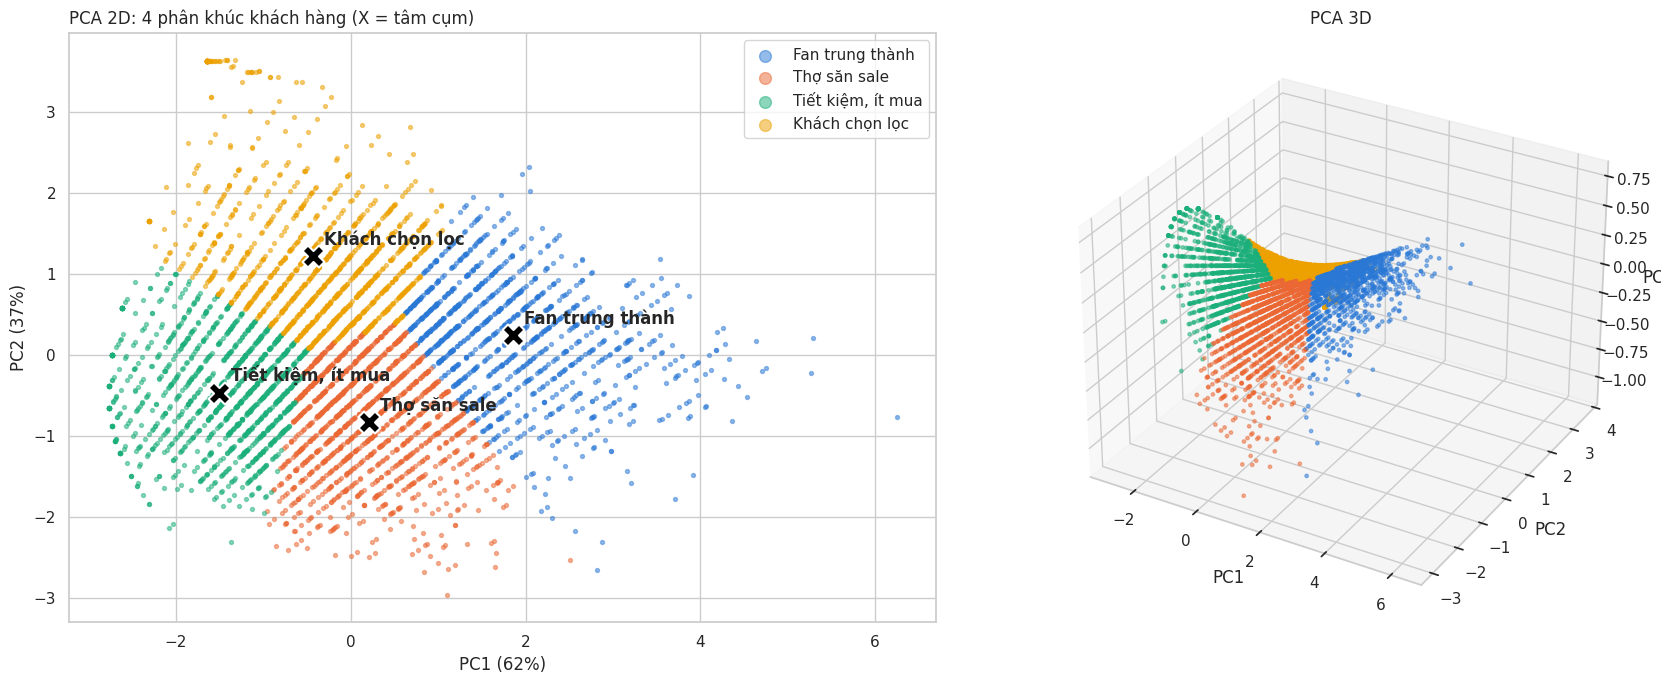

In [17]:
from sklearn.decomposition import PCA

seg_order = ['Fan trung thành', 'Thợ săn sale', 'Tiết kiệm, ít mua', 'Khách chọn lọc']
seg_colors = {'Fan trung thành': '#2a78d6', 'Thợ săn sale': '#eb6834',
              'Tiết kiệm, ít mua': '#1baf7a', 'Khách chọn lọc': '#eda100'}

# PCA 3 thành phần (2D dùng PC1, PC2; 3D dùng thêm PC3)
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)
ev = pca.explained_variance_ratio_
print('Thông tin giữ lại PC1, PC2, PC3:', ev.round(3), '| PC1+PC2 =', round(ev[:2].sum(), 3))
display(pd.DataFrame(pca.components_[:2].T, index=features, columns=['PC1', 'PC2']).round(2))

centers_pca = pca.transform(kmeans.cluster_centers_)
name_of = dict(zip(df['cluster'], df['segment']))

fig = plt.figure(figsize=(18, 7))

# --- Bên trái: 2D ---
ax1 = fig.add_subplot(1, 2, 1)
for s in seg_order:
    m = (df['segment'] == s).values
    ax1.scatter(X_pca[m, 0], X_pca[m, 1], s=8, alpha=0.5, color=seg_colors[s], label=s)
for c, (x, y, _) in enumerate(centers_pca):
    ax1.scatter(x, y, s=250, marker='X', color='black', edgecolor='white', linewidth=1.5)
    ax1.annotate(name_of[c], (x, y), xytext=(8, 8), textcoords='offset points', fontweight='bold')
ax1.set(xlabel=f'PC1 ({ev[0]:.0%})', ylabel=f'PC2 ({ev[1]:.0%})')
ax1.set_title('PCA 2D: 4 phân khúc khách hàng (X = tâm cụm)', loc='left')
ax1.legend(markerscale=3)

# --- Bên phải: 3D ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
for s in seg_order:
    m = (df['segment'] == s).values
    ax2.scatter(X_pca[m, 0], X_pca[m, 1], X_pca[m, 2], s=6, alpha=0.5, color=seg_colors[s], label=s)
ax2.set(xlabel='PC1', ylabel='PC2', zlabel='PC3')
ax2.set_title('PCA 3D')

plt.tight_layout()
plt.savefig(f'{BASE}/outputs/08_pca.png', dpi=150, bbox_inches='tight')
plt.show()

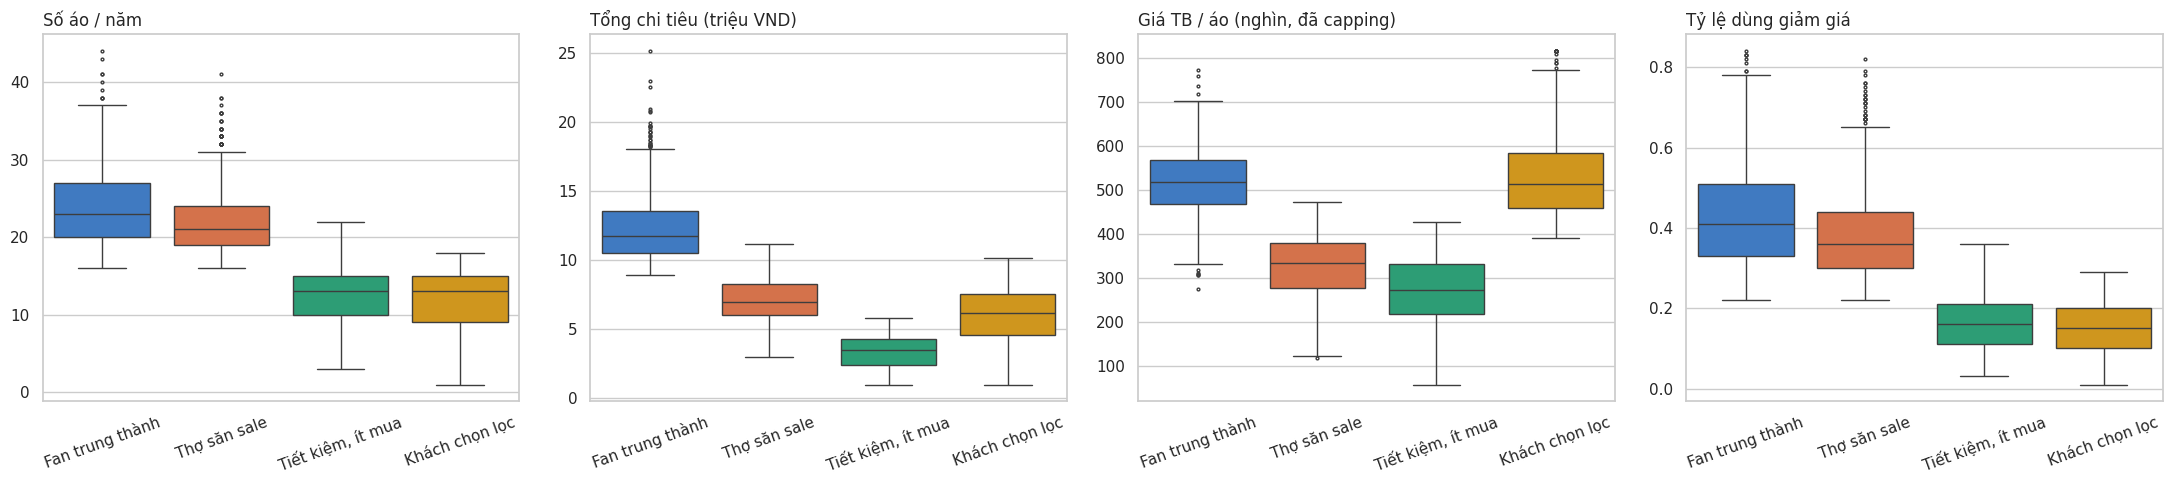

In [18]:
labels_vn = {'total_product_purchase': 'Số áo / năm',
             'total_money_purchase_million_vnd': 'Tổng chi tiêu (triệu VND)',
             'price_per_item_k': 'Giá TB / áo (nghìn, đã capping)',
             'discount_using_rate': 'Tỷ lệ dùng giảm giá'}

plot_df = df.copy()
plot_df['price_per_item_k'] = X['price_per_item_k']   # dùng giá/áo đã capping cho dễ nhìn

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (col, title) in zip(axes, labels_vn.items()):
    sns.boxplot(data=plot_df, x='segment', y=col, order=seg_order,
                hue='segment', palette=seg_colors, legend=False, ax=ax, fliersize=2)
    ax.set_title(title, loc='left'); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig(f'{BASE}/outputs/09_boxplot_by_segment.png', dpi=150, bbox_inches='tight')
plt.show()

**📌 Insight:**
- 2 cụm mua nhiều nhất (Fan trung thành, Thợ săn sale) cũng dùng giảm giá nhiều nhất (38–43%),
  nên chi phí khuyến mãi đang dồn vào nhóm trung thành. Cần thay giảm giá bằng đặc quyền/combo.
- Khách chọn lọc và Tiết kiệm có số áo gần bằng nhau (~11–12), nhưng giá/áo chênh gấp đôi (554k vs 274k).
  Biến **giá/áo** (feature tự tạo) là yếu tố tách được 2 nhóm này.

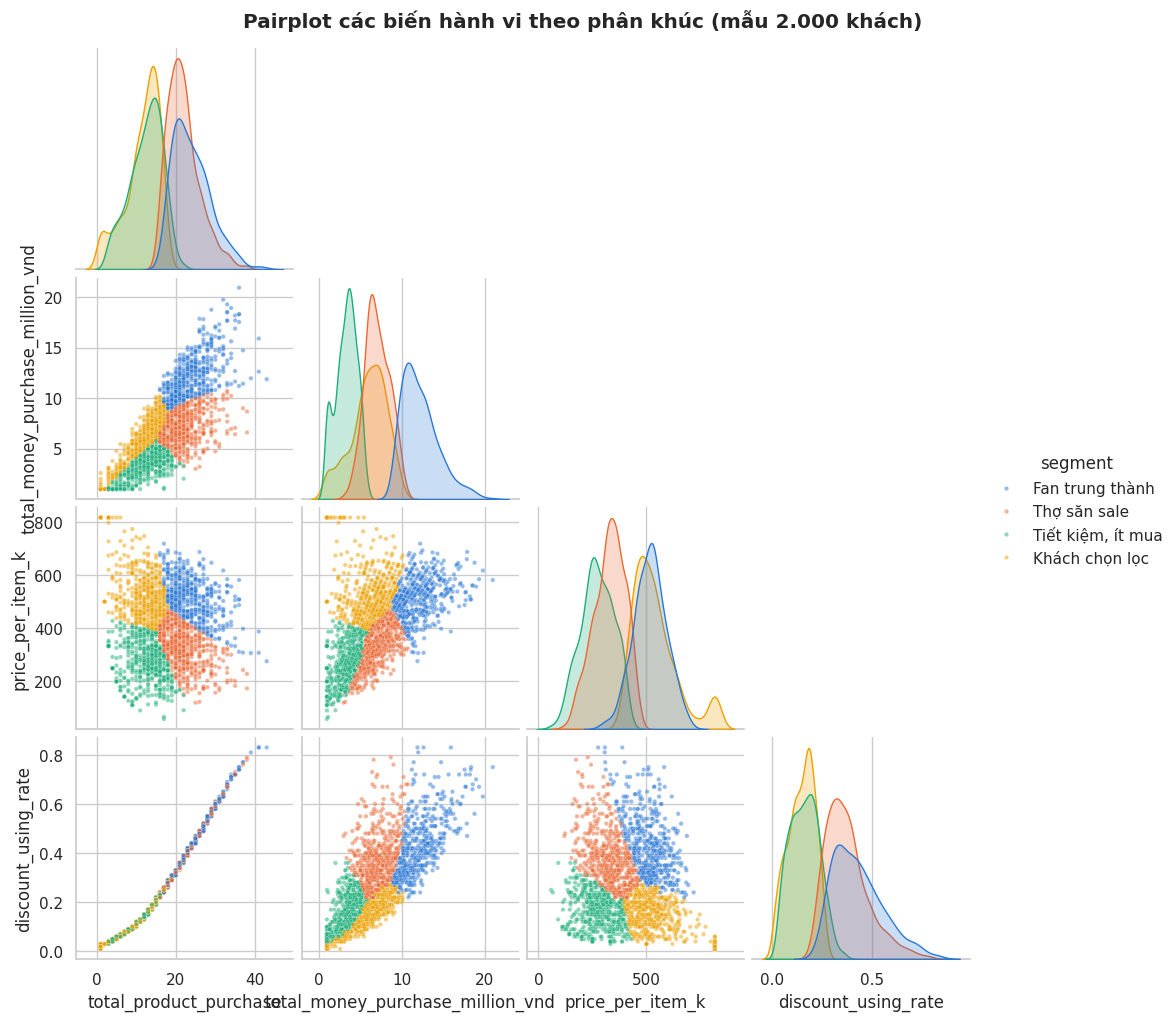

In [19]:
g = sns.pairplot(plot_df.sample(2000, random_state=42),    # lấy mẫu 2.000 khách cho nhẹ và dễ nhìn
                 vars=features + ['discount_using_rate'],
                 hue='segment', hue_order=seg_order, palette=seg_colors,
                 plot_kws={'s': 10, 'alpha': 0.5},
                 corner=True)                                # chỉ vẽ nửa dưới, vì nửa trên lặp lại
g.fig.suptitle('Pairplot các biến hành vi theo phân khúc (mẫu 2.000 khách)',
               y=1.02, fontweight='bold')
g.savefig(f'{BASE}/outputs/10_pairplot.png', dpi=120, bbox_inches='tight')
plt.show()

**📌 Insight (Pairplot):**
- Ô **Số áo × Giá/áo** tách 4 cụm rõ nhất, thành 4 góc của ma trận 2×2 (mua nhiều/ít × áo đắt/rẻ).
- Ô **Số áo × Tỷ lệ giảm giá** là một đường thẳng (r=0.99), chỉ tách được mua nhiều/ít, không phân biệt
  được Fan trung thành với Thợ săn sale. Điều này xác nhận việc loại discount khỏi mô hình là đúng.

## 8. Phụ lục: So sánh thuật toán phân cụm

In [20]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.spatial.distance import cdist

def evaluate(X, labels, name):
    """Tính Silhouette (↑ tốt), Davies-Bouldin (↓ tốt), Overlap ratio (↓ tốt).
       Điểm nhiễu (-1) của DBSCAN được loại ra trước khi tính."""
    mask = labels >= 0
    Xc, lc = X[mask], labels[mask]
    uniq = np.unique(lc)

    # Overlap: % khách mà khoảng cách tới tâm gần thứ 2 < 1.1 lần tâm gần nhất (lơ lửng giữa 2 cụm)
    centroids = np.array([Xc[lc == i].mean(axis=0) for i in uniq])
    d = np.sort(cdist(Xc, centroids), axis=1)
    overlap = np.mean(d[:, 1] / (d[:, 0] + 1e-10) < 1.1)

    return {'Model': name,
            'Số cụm': len(uniq),
            'Silhouette ↑': round(silhouette_score(Xc, lc), 3),
            'Davies-Bouldin ↓': round(davies_bouldin_score(Xc, lc), 3),
            'Overlap % ↓': round(overlap * 100, 1),
            '% nhiễu': round((~mask).mean() * 100, 1),
            'Kích thước cụm': np.bincount(lc).tolist()}

# Đánh giá K-Means trước, làm mốc so sánh
comparison = [evaluate(X_scaled, df['cluster'].values, 'K-Means (K=4)')]
display(pd.DataFrame(comparison))

,Model,Số cụm,Silhouette ↑,Davies-Bouldin ↓,Overlap % ↓,% nhiễu,Kích thước cụm
0,K-Means (K=4),4,0.34,0.89,6.70,0.00,"[1121, 1441, 1230, 1208]"


**📌 K-Means (mốc so sánh):** Silhouette 0.345, Davies-Bouldin 0.887, Overlap 6,7% (~335 khách).
→ 93% khách được phân nhóm rõ ràng. ~335 khách ở ranh giới có thể là nhóm "đang chuyển hạng",
nên theo dõi riêng để upsell sang phân khúc cao hơn.

K,2,3,4,5,6,7,8,9,10
Silhouette,0.33,0.28,0.30,0.24,0.25,0.27,0.28,0.28,0.30


,Model,Số cụm,Silhouette ↑,Davies-Bouldin ↓,Overlap % ↓,% nhiễu,Kích thước cụm
0,K-Means (K=4),4,0.34,0.89,6.70,0.00,"[1121, 1441, 1230, 1208]"
1,"Hierarchical (Ward, K=4)",4,0.30,1.02,7.00,0.00,"[1548, 1004, 1246, 1202]"


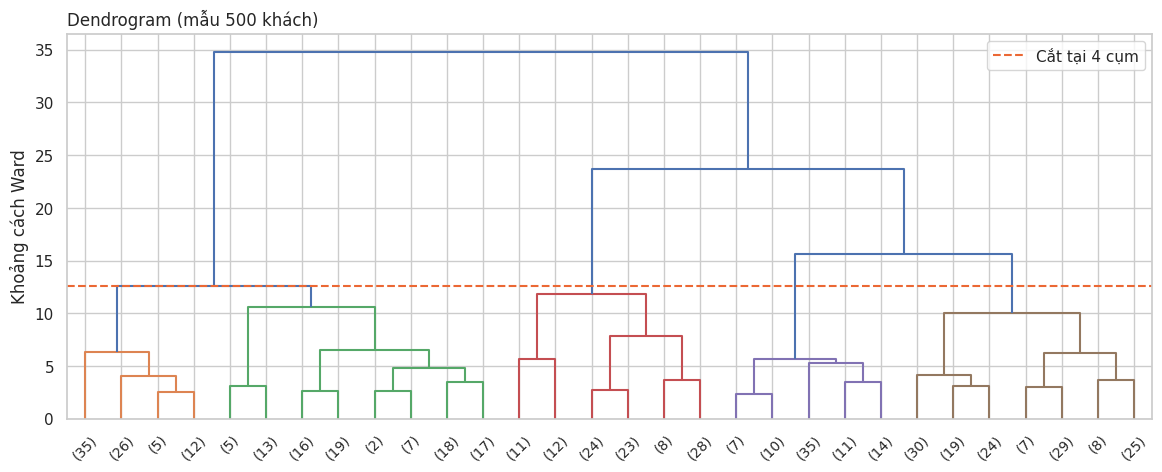

In [21]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Quét K từ 2 đến 10 (giống bài trainer)
hier_sil = []
for k in range(2, 11):
    lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    hier_sil.append({'K': k, 'Silhouette': round(silhouette_score(X_scaled, lab), 3)})
display(pd.DataFrame(hier_sil).set_index('K').T)

# 2. Chạy với K=4 để so sánh công bằng với K-Means
hier_labels = AgglomerativeClustering(n_clusters=4, linkage='ward').fit_predict(X_scaled)
comparison.append(evaluate(X_scaled, hier_labels, 'Hierarchical (Ward, K=4)'))
display(pd.DataFrame(comparison))

# 3. Dendrogram trên mẫu 500 khách (vẽ đủ 5.000 khách sẽ rất chậm và rối)
sample_idx = np.random.RandomState(42).choice(len(X_scaled), 500, replace=False)
Z = linkage(X_scaled[sample_idx], method='ward')

plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30, color_threshold=Z[-4, 2])
plt.axhline(Z[-4, 2], color='#eb6834', ls='--', label='Cắt tại 4 cụm')
plt.title('Dendrogram (mẫu 500 khách)', loc='left')
plt.ylabel('Khoảng cách Ward'); plt.legend()
plt.savefig(f'{BASE}/outputs/11_dendrogram.png', dpi=150, bbox_inches='tight')
plt.show()

**📌 Hierarchical (Ward):** Silhouette cao nhất ở K=2 (0.33), nhưng 2 cụm quá thô cho marketing.
Ở K=4: Silhouette 0.30, DB 1.02, Overlap 7,0%, **kém K-Means ở cả 3 chỉ số**.
Kích thước cụm tương đồng K-Means, gợi ý 2 thuật toán tìm ra cấu trúc gần giống nhau.

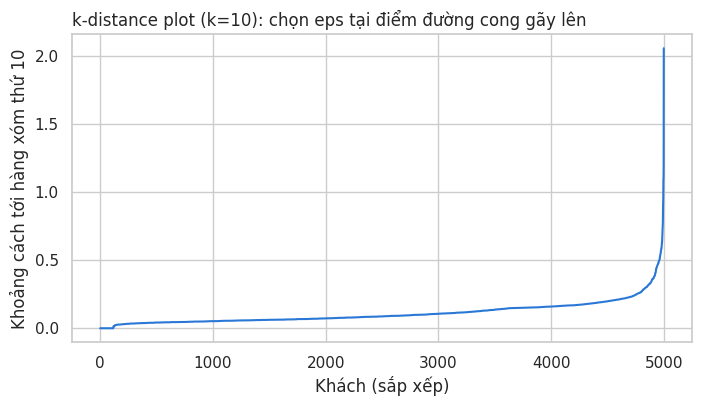

,eps,Số cụm,% nhiễu,Kích thước cụm
0,0.20,7,5.90,"[4560, 71, 22, 20, 11, 12, 10]"
1,0.25,4,2.30,"[4795, 72, 10, 9]"
2,0.30,2,1.60,"[4848, 72]"
3,0.40,2,0.60,"[4895, 75]"
4,0.50,1,0.20,[4992]


,Model,Số cụm,Silhouette ↑,Davies-Bouldin ↓,Overlap % ↓,% nhiễu,Kích thước cụm
0,K-Means (K=4),4,0.34,0.89,6.70,0.00,"[1121, 1441, 1230, 1208]"
1,"Hierarchical (Ward, K=4)",4,0.30,1.02,7.00,0.00,"[1548, 1004, 1246, 1202]"
2,DBSCAN (eps=0.3),2,0.51,0.41,1.10,1.60,"[4848, 72]"


In [22]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# 1. k-distance plot: khoảng cách từ mỗi khách tới hàng xóm thứ 10, sắp xếp tăng dần
min_samples = 10
dist = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled).kneighbors(X_scaled)[0][:, -1]

plt.figure(figsize=(8, 4))
plt.plot(np.sort(dist), color='#2a78d6')
plt.title(f'k-distance plot (k={min_samples}): chọn eps tại điểm đường cong gãy lên', loc='left')
plt.xlabel('Khách (sắp xếp)'); plt.ylabel(f'Khoảng cách tới hàng xóm thứ {min_samples}')
plt.savefig(f'{BASE}/outputs/12_kdistance.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. Thử nhiều giá trị eps
rows = []
for eps in [0.2, 0.25, 0.3, 0.4, 0.5]:
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    core = lab[lab >= 0]
    rows.append({'eps': eps,
                 'Số cụm': len(set(core)),
                 '% nhiễu': round((lab == -1).mean() * 100, 1),
                 'Kích thước cụm': np.bincount(core).tolist() if len(core) else []})
display(pd.DataFrame(rows))

# 3. Chọn eps=0.3 để đánh giá
dbscan_labels = DBSCAN(eps=0.3, min_samples=min_samples).fit_predict(X_scaled)
comparison.append(evaluate(X_scaled, dbscan_labels, 'DBSCAN (eps=0.3)'))
display(pd.DataFrame(comparison))

In [23]:
small = df[dbscan_labels == 1]
print('Số khách trong cụm nhỏ:', len(small))
print('Số khách bị capping giá/áo (=816k):', (X['price_per_item_k'] >= upper - 0.01).sum())
display(small[['total_product_purchase', 'total_money_purchase_million_vnd']].describe().round(2))
print('Giá/áo sau capping của cụm nhỏ:', X.loc[small.index, 'price_per_item_k'].round(0).value_counts().head())

Số khách trong cụm nhỏ: 72
Số khách bị capping giá/áo (=816k): 74


,total_product_purchase,total_money_purchase_million_vnd
count,72.00,72.00
mean,1.40,1.47
std,0.87,0.75
min,1.00,1.00
25%,1.00,1.00
50%,1.00,1.00
75%,1.00,1.77
max,4.00,3.78


Giá/áo sau capping của cụm nhỏ: price_per_item_k
816.00    71
797.00     1
Name: count, dtype: int64


**📌 DBSCAN:** Ở mọi eps, DBSCAN gom >91% khách vào 1 cụm, nên dữ liệu là một khối liên tục, không có vùng thưa để tách.
Với eps=0.3: Silhouette 0.51, Overlap 1,1%, **cao nhất trên giấy, nhưng không dùng được**:
- Chỉ có 2 cụm (4.848 vs 72 khách), không đủ để làm ưu đãi riêng.
- Cụm 72 khách là **artifact của bước capping**: các khách mua 1 áo bị chặn giá/áo đúng tại 816k,
  dồn về một điểm nên DBSCAN coi là vùng dày đặc.
→ **Bài học: chỉ số đẹp ≠ phân khúc tốt.** Luôn kiểm tra kích thước và ý nghĩa của cụm trước khi chọn mô hình.

In [24]:
from sklearn.mixture import GaussianMixture

# 1. Quét K bằng BIC và Silhouette
gmm_rows = []
for k in range(2, 11):
    gm = GaussianMixture(n_components=k, covariance_type='full', random_state=42).fit(X_scaled)
    gmm_rows.append({'K': k,
                     'BIC ↓': round(gm.bic(X_scaled)),
                     'Silhouette ↑': round(silhouette_score(X_scaled, gm.predict(X_scaled)), 3)})
display(pd.DataFrame(gmm_rows).set_index('K').T)

# 2. Chạy với K=4 để so sánh
gmm = GaussianMixture(n_components=4, covariance_type='full', random_state=42).fit(X_scaled)
gmm_labels = gmm.predict(X_scaled)
comparison.append(evaluate(X_scaled, gmm_labels, 'GMM (K=4)'))
display(pd.DataFrame(comparison))

# 3. Điểm mạnh riêng của GMM: xác suất thuộc cụm
proba = gmm.predict_proba(X_scaled).max(axis=1)
print(f'Tỷ lệ khách được GMM gán với độ chắc chắn < 60%: {(proba < 0.6).mean():.1%}')

K,2,3,4,5,6,7,8,9,10
BIC ↓,25742.00,20504.00,17819.00,15394.00,13117.00,12165.00,10291.00,9595.00,8277.00
Silhouette ↑,0.29,0.31,0.26,0.32,0.28,0.28,0.25,0.29,0.27


,Model,Số cụm,Silhouette ↑,Davies-Bouldin ↓,Overlap % ↓,% nhiễu,Kích thước cụm
0,K-Means (K=4),4,0.34,0.89,6.70,0.00,"[1121, 1441, 1230, 1208]"
1,"Hierarchical (Ward, K=4)",4,0.30,1.02,7.00,0.00,"[1548, 1004, 1246, 1202]"
2,DBSCAN (eps=0.3),2,0.51,0.41,1.10,1.60,"[4848, 72]"
3,GMM (K=4),4,0.26,1.21,8.60,0.00,"[542, 1315, 1377, 1766]"


Tỷ lệ khách được GMM gán với độ chắc chắn < 60%: 6.0%


**📌 GMM:** BIC giảm liên tục từ K=2→10, không có điểm dừng, do dữ liệu có cấu trúc lưới
(số áo là số nguyên) và điểm dồn capping; GMM thêm cụm để khớp các mẫu này, không phải nhóm khách thật.
Ở K=4: Silhouette 0.26, DB 1.21, Overlap 8,6%, **kém nhất**; kích thước cụm lệch (542–1.766).
Điểm cộng: 6% khách có xác suất thuộc cụm < 60%, khớp với Overlap 6,7% của K-Means.
Hai phương pháp độc lập cùng xác nhận ~6–7% khách ở vùng ranh giới.

,Model,Số cụm,Silhouette ↑,Davies-Bouldin ↓,Overlap % ↓,% nhiễu,Kích thước cụm,Giống K-Means (ARI)
0,K-Means (K=4),4,0.34,0.89,6.70,0.00,"[1121, 1441, 1230, 1208]",1.00
1,"Hierarchical (Ward, K=4)",4,0.30,1.02,7.00,0.00,"[1548, 1004, 1246, 1202]",0.58
2,DBSCAN (eps=0.3),2,0.51,0.41,1.10,1.60,"[4848, 72]",0.00
3,GMM (K=4),4,0.26,1.21,8.60,0.00,"[542, 1315, 1377, 1766]",0.47


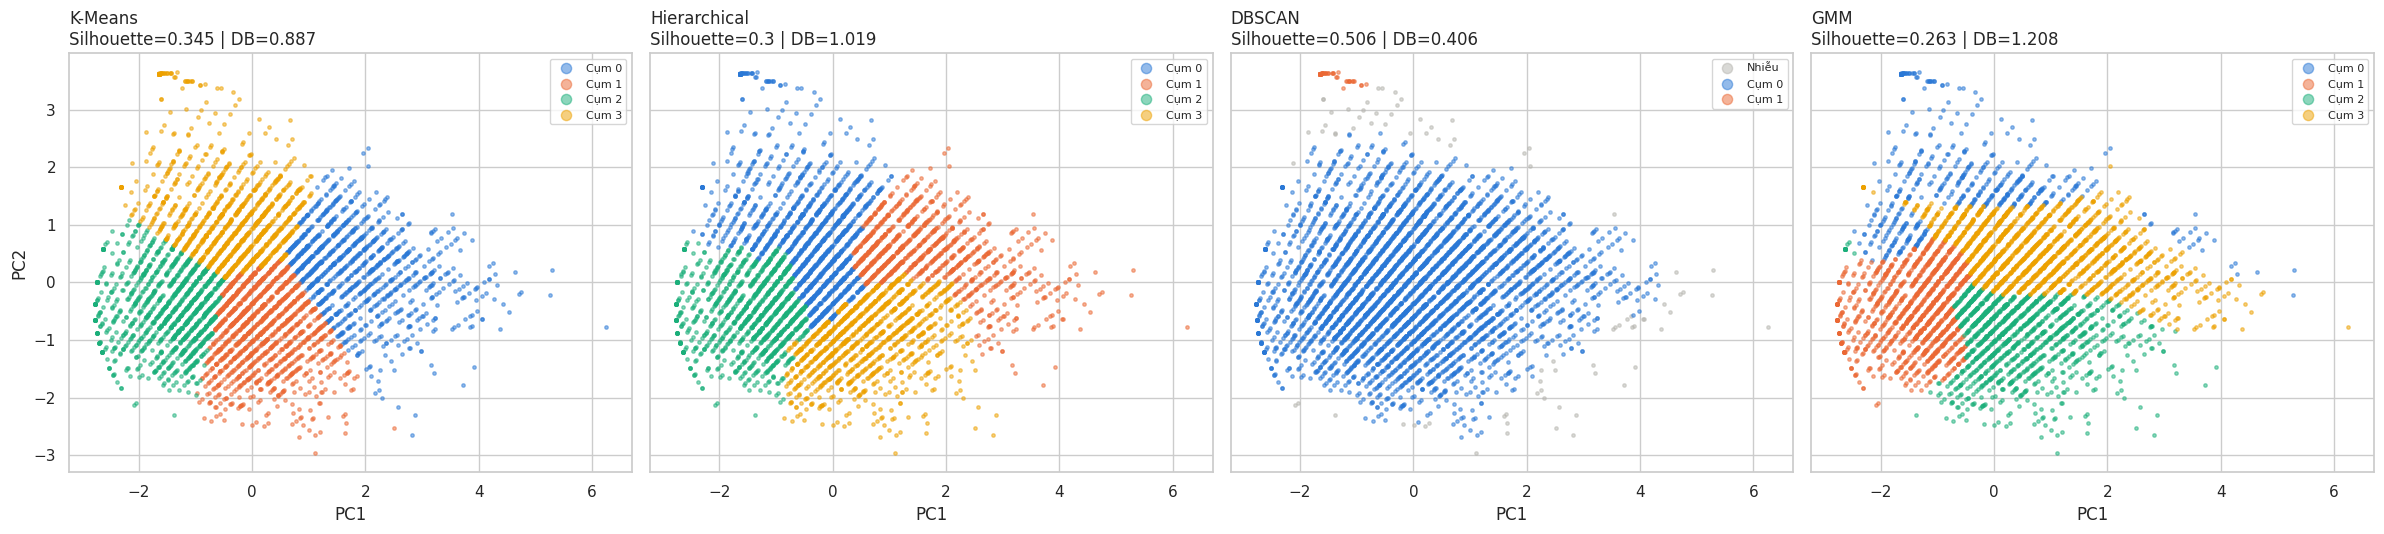

In [25]:
from sklearn.metrics import adjusted_rand_score

# 1. Bảng tổng hợp + ARI
comp_df = pd.DataFrame(comparison)
comp_df['Giống K-Means (ARI)'] = [
    1.0,
    round(adjusted_rand_score(df['cluster'], hier_labels), 3),
    round(adjusted_rand_score(df['cluster'], dbscan_labels), 3),
    round(adjusted_rand_score(df['cluster'], gmm_labels), 3)]
display(comp_df)

# 2. 4 biểu đồ PCA cạnh nhau
fig, axes = plt.subplots(1, 4, figsize=(24, 5.5), sharex=True, sharey=True)
pal = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
models = [('K-Means', df['cluster'].values), ('Hierarchical', hier_labels),
          ('DBSCAN', dbscan_labels), ('GMM', gmm_labels)]

for ax, (name, lab) in zip(axes, models):
    for c in np.unique(lab):
        m = lab == c
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=6, alpha=0.5,
                   color='#b5b4ae' if c == -1 else pal[c % 4],
                   label='Nhiễu' if c == -1 else f'Cụm {c}')
    row = comp_df[comp_df['Model'].str.startswith(name)].iloc[0]
    ax.set_title(f"{name}\nSilhouette={row['Silhouette ↑']} | DB={row['Davies-Bouldin ↓']}", loc='left')
    ax.set_xlabel('PC1'); ax.legend(markerscale=3, fontsize=8)
axes[0].set_ylabel('PC2')
plt.tight_layout()
plt.savefig(f'{BASE}/outputs/13_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.5 Kết luận chọn mô hình

| Model | Số cụm | Silhouette ↑ | DB ↓ | Overlap ↓ | ARI vs K-Means | Đánh giá |
|---|---|---|---|---|---|---|
| **K-Means** | 4 | **0.345** | **0.887** | **6,7%** | 1.00 | ✅ **Chọn** |
| Hierarchical | 4 | 0.300 | 1.019 | 7,0% | 0.58 | Kém hơn ở cả 3 chỉ số |
| GMM | 4 | 0.263 | 1.208 | 8,6% | 0.47 | Kém nhất; BIC không hội tụ |
| DBSCAN | 2 | 0.506 | 0.406 | 1,1% | 0.00 | ❌ Chỉ số đẹp nhưng cụm vô nghĩa |

**Chọn K-Means vì:**
1. **Tốt nhất trên cả 3 chỉ số** trong các mô hình chia được 4 cụm.
2. **Kết quả ổn định:** Hierarchical (nguyên lý khác hoàn toàn) cho cấu trúc tương tự (ARI 0.58).
3. **Kích thước cụm cân bằng** (1.121–1.441 khách), đủ lớn để triển khai và đo lường A/B test.
4. **Dễ vận hành:** khách mới được gán phân khúc ngay bằng `kmeans.predict()`; tâm cụm dễ giải thích cho marketing.

**Bài học:** DBSCAN có Silhouette cao nhất (0.51) nhưng gom 97% khách vào 1 cụm, và cụm còn lại
là artifact của bước

## 9. Phụ lục: Phân cụm theo nhân khẩu học vs theo hành vi

In [26]:
# Cách tiếp cận theo nhân khẩu học (bộ biến của bài mẫu khóa học)
demo_features = ['total_money_purchase_million_vnd', 'income_million_vnd', 'age']
X_demo = StandardScaler().fit_transform(df[demo_features])
df['cluster_demo'] = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_demo)

# Xem HÀNH VI MUA của từng cụm nhân khẩu học
demo_profile = df.groupby('cluster_demo').agg(
    tuoi=('age', 'mean'),
    thu_nhap=('income_million_vnd', 'mean'),
    chi_tieu=('total_money_purchase_million_vnd', 'mean'),
    so_ao=('total_product_purchase', 'mean'),
    gia_ao=('price_per_item_k', 'mean'),
    giam_gia=('discount_using_rate', 'mean'),
    online=('buying_channel', lambda s: (s == 'Online').mean()),
    so_khach=('customer_id', 'count')).round(2)
display(demo_profile)

# So sánh chất lượng 2 cách tiếp cận
print('Theo nhân khẩu học  → Silhouette:', round(silhouette_score(X_demo, df['cluster_demo']), 3),
      '| DB:', round(davies_bouldin_score(X_demo, df['cluster_demo']), 3))
print('Theo hành vi (bài này) → Silhouette:', round(silhouette_score(X_scaled, df['cluster']), 3),
      '| DB:', round(davies_bouldin_score(X_scaled, df['cluster']), 3))

,tuoi,thu_nhap,chi_tieu,so_ao,gia_ao,giam_gia,online,so_khach
cluster_demo,,,,,,,,
0,41.83,12.39,6.53,16.73,407.29,0.26,0.32,878
1,22.05,10.19,4.88,14.61,368.61,0.22,0.30,2088
2,22.94,11.60,11.61,23.68,499.05,0.42,0.30,1181
3,23.93,30.25,6.59,17.14,401.35,0.27,0.32,853


Theo nhân khẩu học  → Silhouette: 0.317 | DB: 0.986
Theo hành vi (bài này) → Silhouette: 0.345 | DB: 0.887


**📌 So sánh 2 cách tiếp cận:**
Phân cụm theo nhân khẩu học (chi tiêu + tuổi + thu nhập) tạo ra cụm "Lớn tuổi" (41,8 tuổi) và
"Thu nhập cao" (30,3tr) **có hành vi mua gần như giống hệt nhau** (chi tiêu 6,53 vs 6,59tr,
giá/áo 407k vs 401k, giảm giá 26% vs 27%, online 32% vs 32%).
→ 2 cụm này sẽ nhận cùng một ưu đãi, nên tách ra chỉ tăng chi phí vận hành, không tăng hiệu quả.

Phân cụm theo hành vi cho 4 nhóm khác biệt rõ về số lượng, giá áo và mức dùng giảm giá,
mỗi nhóm có chiến lược riêng; đồng thời chỉ số tốt hơn (Silhouette 0.345 vs 0.317, DB 0.887 vs 0.986).
→ **Phân khúc theo hành vi phục vụ mục tiêu "giảm lãng phí chi phí marketing" tốt hơn.**

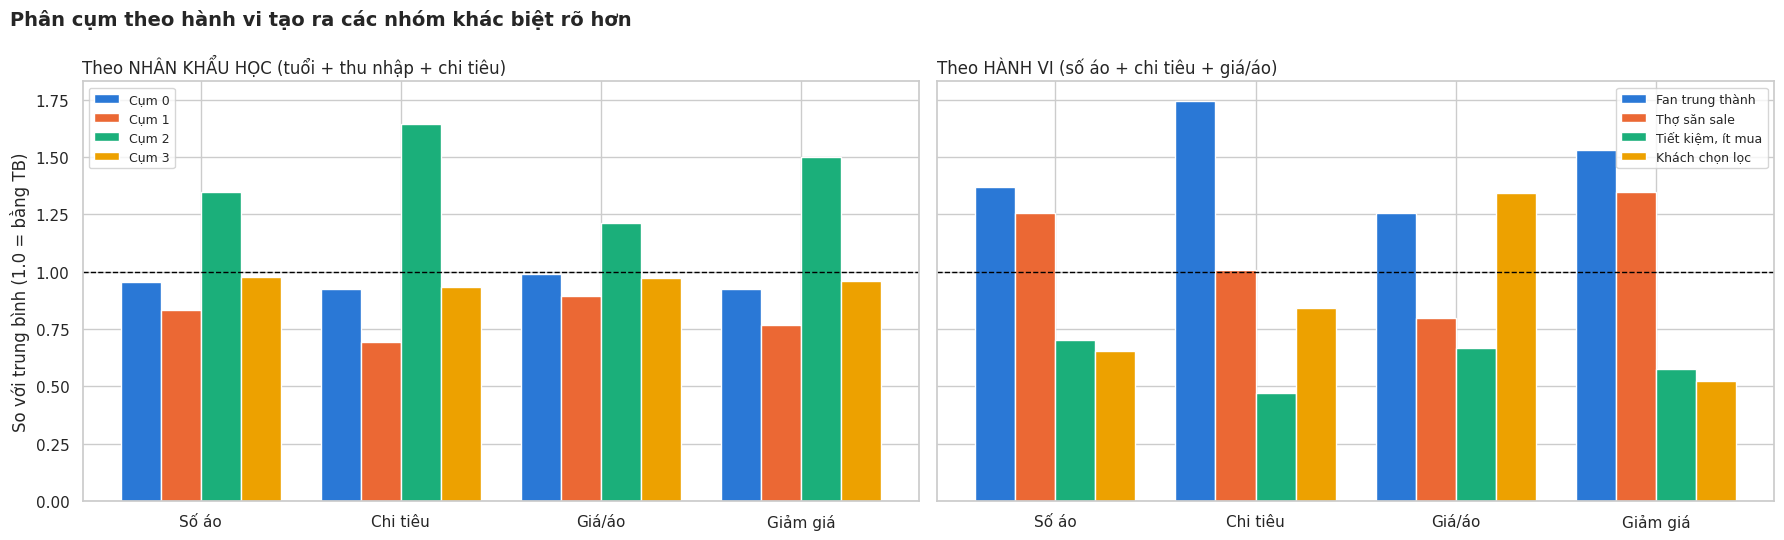

In [27]:
behav = ['total_product_purchase', 'total_money_purchase_million_vnd',
         'price_per_item_k', 'discount_using_rate']
behav_vn = ['Số áo', 'Chi tiêu', 'Giá/áo', 'Giảm giá']
pal = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), sharey=True)
for ax, (col, title) in zip(axes, [('cluster_demo', 'Theo NHÂN KHẨU HỌC (tuổi + thu nhập + chi tiêu)'),
                                   ('cluster', 'Theo HÀNH VI (số áo + chi tiêu + giá/áo)')]):
    idx = df.groupby(col)[behav].mean() / df[behav].mean()   # chỉ số so với trung bình
    x = np.arange(len(behav)); w = 0.2
    for i, c in enumerate(idx.index):
        label = f'Cụm {c}' if col == 'cluster_demo' else cluster_names[c]
        ax.bar(x + (i - 1.5) * w, idx.loc[c], w, color=pal[i], label=label)
    ax.axhline(1, color='black', lw=1, ls='--')
    ax.set_xticks(x, behav_vn); ax.set_title(title, loc='left'); ax.legend(fontsize=9)
axes[0].set_ylabel('So với trung bình (1.0 = bằng TB)')
fig.suptitle('Phân cụm theo hành vi tạo ra các nhóm khác biệt rõ hơn', x=0.01, ha='left',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{BASE}/outputs/14_demo_vs_behavior.png', dpi=150, bbox_inches='tight')
plt.show()

**📌 Insight:** Theo nhân khẩu học, 2/4 cụm (0 và 3) bám sát mức trung bình ở mọi chỉ số hành vi,
nên thực chất chỉ tìm ra 2 nhóm có ý nghĩa. Theo hành vi, cả 4 cụm đều lệch rõ khỏi trung bình,
mỗi cụm có "dấu vân tay" riêng, đủ để thiết kế 4 chiến lược ưu đãi khác nhau.
Ví dụ: "Thợ săn sale" có tổng chi tiêu đúng bằng TB, nên chỉ phát hiện được nhờ tách số áo và giá/áo.